# Credit Card Fraud Detection

Binary classification of credit card transactions as fraudulent or legitimate on a highly imbalanced dataset (0.17 % fraud).
The notebook compares **logistic regression**, a **decision tree** and a **random forest**, trained on the original class distribution and with **SMOTE** oversampling, and tunes the first two with cross-validated grid search.

**Methodology.** The data are split into a training and a test set *before* any scaling or resampling. Scaling and SMOTE are steps of a pipeline that is fitted on the training data only (inside every cross-validation fold during tuning), and all models are evaluated on the untouched test set with its real class distribution. Because accuracy and ROC-AUC look excellent on data this imbalanced even for weak models, the main metric is **PR-AUC** (average precision), together with precision and recall for the fraud class.

## 1. Data

The [Credit Card Fraud Detection dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (ULB Machine Learning Group) contains transactions made by European cardholders over two days in September 2013: 492 frauds out of 284,807 transactions.

- `V1` … `V28`: principal components of the original features (the original features are confidential).
- `Time`: seconds elapsed since the first transaction in the dataset.
- `Amount`: transaction amount.
- `Class`: 1 for fraud, 0 otherwise.

Download `creditcard.csv` from Kaggle and put it into `data/`, or set `DATA_PATH` below (e.g. to a Google Drive folder in Colab).

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = Path("/content/drive/MyDrive/creditcard.csv")  # change to your Drive folder
else:
    DATA_PATH = Path("data/creditcard.csv")

FIG_DIR = Path("docs")
FIG_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

creditcard = pd.read_csv(DATA_PATH)
creditcard.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
creditcard.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
creditcard.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.759088e-12,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,-8.251210e-13,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-9.655224e-13,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,8.321417e-13,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.650335e-13,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,4.248462e-13,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-3.054652e-13,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,8.777941e-14,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-1.179734e-12,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [5]:
counts = creditcard["Class"].value_counts()
print(counts)
print(f"Fraud share: {counts[1] / counts.sum():.3%}")

Class
0    284315
1       492
Name: count, dtype: int64
Fraud share: 0.173%


## 2. Data cleaning

In [6]:
print("Missing values:", creditcard.isna().sum().sum())
print("Duplicate rows:", creditcard.duplicated().sum())

# reset_index keeps the row labels aligned after rows are dropped
creditcard = creditcard.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(creditcard))
print(creditcard["Class"].value_counts())

Missing values: 0


Duplicate rows: 1081


Rows after removing duplicates: 283726
Class
0    283253
1       473
Name: count, dtype: int64


There are no missing values. The duplicate rows are removed so that identical transactions cannot end up in both the training and the test set. Scaling is done later, inside the model pipelines, so that it is fitted on the training data only.

## 3. Hypothesis test: is fraud timed differently?

- **H0:** the time distribution of fraudulent and legitimate transactions is the same.
- **H1:** the distributions differ.

`Time` counts seconds from the first transaction over two days, so it is converted to the hour of the day. The Kolmogorov–Smirnov test compares the whole distributions and Welch's t-test the means; with p < 0.05 we reject H0.

Kolmogorov-Smirnov: statistic = 0.1911, p = 1.45e-15
Welch's t-test:     statistic = 7.8922, p = 2.08e-14


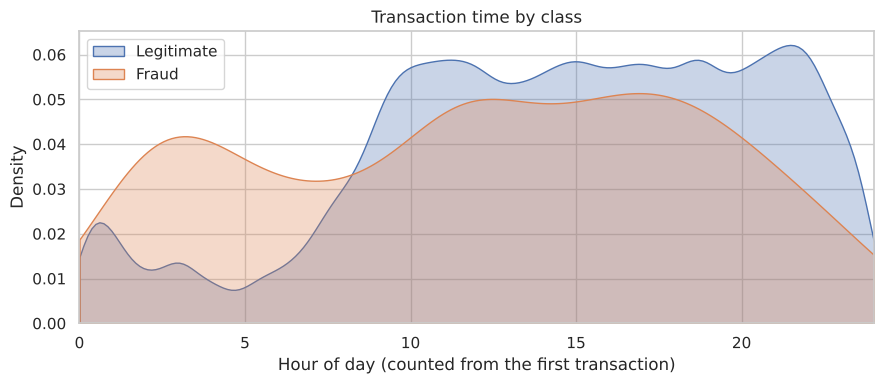

In [7]:
from scipy.stats import ks_2samp, ttest_ind

hour = (creditcard["Time"] % 86400) / 3600
hour_legit = hour[creditcard["Class"] == 0]
hour_fraud = hour[creditcard["Class"] == 1]

ks_stat, p_ks = ks_2samp(hour_legit, hour_fraud)
t_stat, p_t = ttest_ind(hour_legit, hour_fraud, equal_var=False)
print(f"Kolmogorov-Smirnov: statistic = {ks_stat:.4f}, p = {p_ks:.2e}")
print(f"Welch's t-test:     statistic = {t_stat:.4f}, p = {p_t:.2e}")

fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(hour_legit, ax=ax, label="Legitimate", fill=True, alpha=0.3, clip=(0, 24))
sns.kdeplot(hour_fraud, ax=ax, label="Fraud", fill=True, alpha=0.3, clip=(0, 24))
ax.set(xlabel="Hour of day (counted from the first transaction)", ylabel="Density",
       title="Transaction time by class", xlim=(0, 24))
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "time_by_class.png", dpi=120)
plt.show()

Both p-values are far below 0.05, so **H0 is rejected**: fraudulent transactions are distributed differently over the day than legitimate ones.

- Legitimate transactions drop sharply between about hour 1 and hour 8 (most likely the night) and peak in the evening.
- Fraud is spread much more evenly: a large share of it happens in the hours when legitimate activity is lowest, so the *proportion* of fraud is highest at night.
- With 473 frauds even a moderate difference is highly significant; the KS statistic of 0.19 shows a clear but not dramatic difference. Time of day could be a useful engineered feature, but on its own it does not separate the classes.

## 4. Exploratory analysis

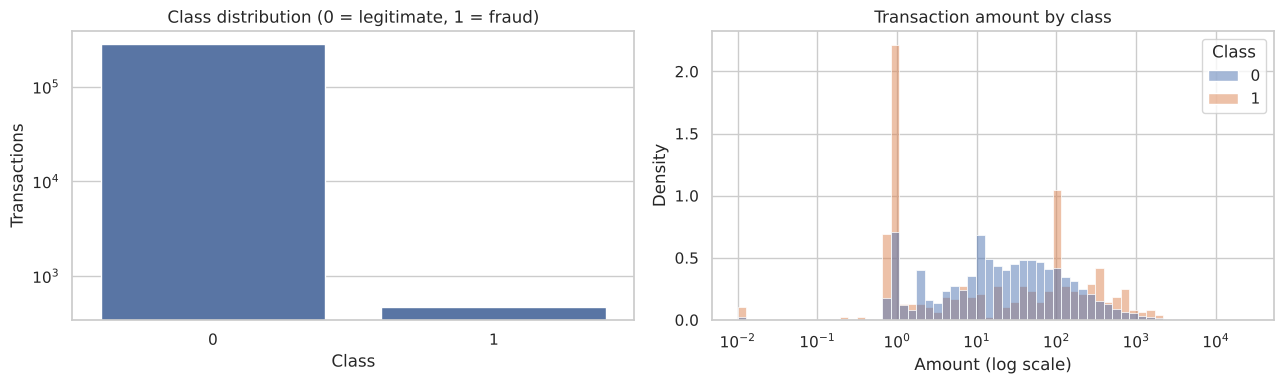

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=creditcard["Class"], ax=axes[0])
axes[0].set(title="Class distribution (0 = legitimate, 1 = fraud)", xlabel="Class", ylabel="Transactions")
axes[0].set_yscale("log")

sns.histplot(data=creditcard, x="Amount", hue="Class", bins=60, stat="density",
             common_norm=False, log_scale=(True, False), ax=axes[1])
axes[1].set(title="Transaction amount by class", xlabel="Amount (log scale)")
fig.tight_layout()
plt.show()

print(creditcard.groupby("Class")["Amount"].describe())

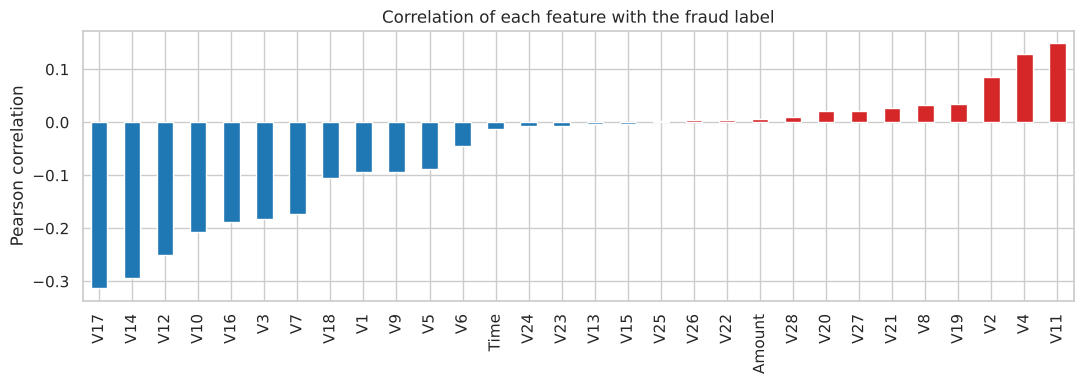

In [9]:
corr_with_class = creditcard.drop(columns=["Class"]).corrwith(creditcard["Class"]).sort_values()

fig, ax = plt.subplots(figsize=(11, 4))
corr_with_class.plot.bar(ax=ax, color=np.where(corr_with_class < 0, "tab:blue", "tab:red"))
ax.set(title="Correlation of each feature with the fraud label", ylabel="Pearson correlation")
fig.tight_layout()
plt.show()

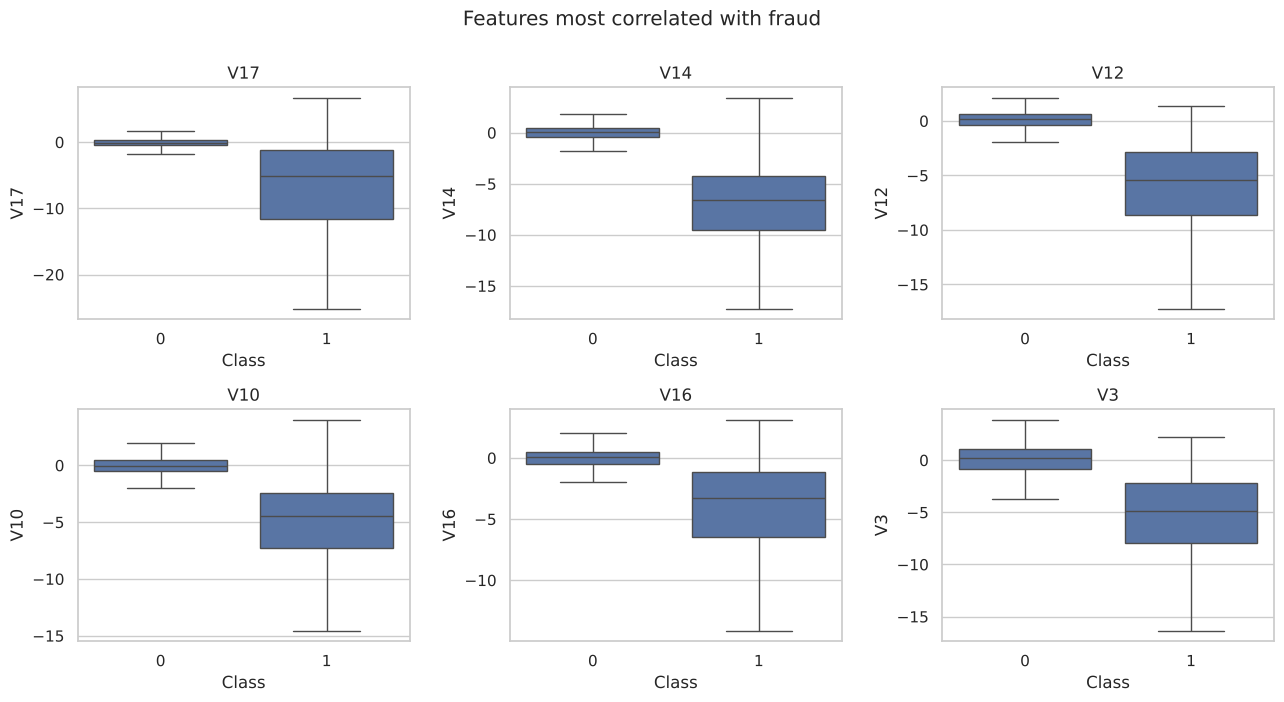

In [10]:
top_features = corr_with_class.abs().sort_values(ascending=False).index[:6]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.ravel(), top_features):
    sns.boxplot(data=creditcard, x="Class", y=feature, ax=ax, showfliers=False)
    ax.set_title(feature)
fig.suptitle("Features most correlated with fraud", y=1.0)
fig.tight_layout()
plt.show()

- Only 473 of 283,726 transactions (0.17 %) are fraud, so a model that always predicts "legitimate" is 99.8 % accurate. Accuracy is therefore not used to compare models.
- Fraudulent amounts have a lower median (9.82 vs. 22.00) but a higher mean (123.87 vs. 88.41) than legitimate ones, with peaks at round values around 1 and 100.
- Several PCA components separate the classes well: `V17`, `V14`, `V12`, `V10`, `V16` and `V3` are strongly negative for most frauds and close to zero for legitimate transactions.

## 5. Train/test split and evaluation

`Time` is dropped from the model features: it only counts seconds from the start of the two-day recording, so it would not carry over to new data. The split is stratified so that both sets keep the 0.17 % fraud share.

In [11]:
from sklearn.model_selection import train_test_split

X = creditcard.drop(columns=["Class", "Time"])
y = creditcard["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} rows, {y_train.sum()} frauds")
print(f"Test:  {len(X_test):,} rows, {y_test.sum()} frauds")

Train: 226,980 rows, 378 frauds
Test:  56,746 rows, 95 frauds


In [12]:
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)

results = {}
fitted = {}


def evaluate(name, model):
    """Evaluates a fitted model on the test set and stores the metrics."""
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    results[name] = {
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
        "frauds_caught": f"{tp}/{tp + fn}",
        "false_alarms": fp,
    }
    fitted[name] = model
    print(name)
    print(classification_report(y_test, pred, target_names=["legitimate", "fraud"], digits=3))
    print(f"ROC-AUC = {results[name]['roc_auc']:.3f}   PR-AUC = {results[name]['pr_auc']:.3f}   "
          f"false alarms = {fp}, missed frauds = {fn}\n")

## 6. Models on the original (imbalanced) data

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

logreg = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
evaluate("Logistic regression", logreg)

tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
evaluate("Decision tree", tree)

Logistic regression
              precision    recall  f1-score   support

  legitimate      0.999     1.000     1.000     56651
       fraud      0.846     0.579     0.688        95

    accuracy                          0.999     56746
   macro avg      0.923     0.789     0.844     56746
weighted avg      0.999     0.999     0.999     56746

ROC-AUC = 0.956   PR-AUC = 0.692   false alarms = 10, missed frauds = 40



Decision tree
              precision    recall  f1-score   support

  legitimate      0.999     1.000     1.000     56651
       fraud      0.714     0.684     0.699        95

    accuracy                          0.999     56746
   macro avg      0.857     0.842     0.849     56746
weighted avg      0.999     0.999     0.999     56746

ROC-AUC = 0.842   PR-AUC = 0.489   false alarms = 26, missed frauds = 30



A decision tree does not need scaled features, so it is trained on the raw values. Both models reach an accuracy above 99.9 %, but that alone means little: predicting "legitimate" for every transaction would score 99.8 %. The fraud-class metrics show what the models actually catch.

## 7. Models with SMOTE oversampling

SMOTE creates synthetic fraud examples by interpolating between neighbouring frauds. It is a step of an `imblearn` pipeline, so it is applied **only to the training data** when the pipeline is fitted; the test set keeps the real class distribution. (Applying SMOTE to the whole dataset before splitting would put synthetic copies of test frauds into the training data and inflate the scores.)

In [14]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

logreg_smote = ImbPipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
evaluate("Logistic regression + SMOTE", logreg_smote)

tree_smote = ImbPipeline([
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
evaluate("Decision tree + SMOTE", tree_smote)

Logistic regression + SMOTE
              precision    recall  f1-score   support

  legitimate      1.000     0.974     0.987     56651
       fraud      0.053     0.874     0.099        95

    accuracy                          0.973     56746
   macro avg      0.526     0.924     0.543     56746
weighted avg      0.998     0.973     0.985     56746

ROC-AUC = 0.960   PR-AUC = 0.676   false alarms = 1493, missed frauds = 12



Decision tree + SMOTE
              precision    recall  f1-score   support

  legitimate      1.000     0.997     0.998     56651
       fraud      0.318     0.716     0.440        95

    accuracy                          0.997     56746
   macro avg      0.659     0.857     0.719     56746
weighted avg      0.998     0.997     0.998     56746

ROC-AUC = 0.857   PR-AUC = 0.228   false alarms = 146, missed frauds = 27



SMOTE moves the models towards **higher recall at the cost of precision**:

- Logistic regression catches 83 instead of 55 of the 95 test frauds, but raises 1,493 false alarms instead of 10 (precision drops from 0.85 to 0.05).
- The decision tree catches 68 instead of 65 frauds with 146 instead of 26 false alarms, and its PR-AUC drops from 0.49 to 0.23.

So SMOTE does not make the models better at *ranking* transactions by risk (PR-AUC does not improve); it mainly shifts the decision threshold. A similar trade-off can be chosen directly by lowering the threshold of a model trained on the original data. The grid search below lets cross-validation decide whether SMOTE is used.

## 8. Hyperparameter tuning

`GridSearchCV` with stratified 5-fold cross-validation on the training set only. SMOTE is part of the pipeline, so in every fold it is fitted on the training part and the validation part stays untouched. The search optimises **average precision** (PR-AUC).

- **Logistic regression:** regularisation strength `C`, with or without SMOTE.
- **Decision tree:** maximum depth and minimum samples per leaf, with or without SMOTE.

In [15]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

logreg_search = GridSearchCV(
    ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    param_grid={
        "smote": [SMOTE(random_state=RANDOM_STATE), "passthrough"],
        "model__C": [0.01, 0.1, 1, 10],
    },
    scoring="average_precision", cv=cv, n_jobs=-1,
).fit(X_train, y_train)

print("Best parameters:", logreg_search.best_params_)
print(f"Best cross-validated PR-AUC: {logreg_search.best_score_:.3f}\n")
evaluate("Logistic regression (tuned)", logreg_search.best_estimator_)

Best parameters: {'model__C': 0.1, 'smote': 'passthrough'}
Best cross-validated PR-AUC: 0.754

Logistic regression (tuned)
              precision    recall  f1-score   support

  legitimate      0.999     1.000     1.000     56651
       fraud      0.846     0.579     0.688        95

    accuracy                          0.999     56746
   macro avg      0.923     0.789     0.844     56746
weighted avg      0.999     0.999     0.999     56746

ROC-AUC = 0.956   PR-AUC = 0.692   false alarms = 10, missed frauds = 40



In [16]:
tree_search = GridSearchCV(
    ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    param_grid={
        "smote": [SMOTE(random_state=RANDOM_STATE), "passthrough"],
        "model__max_depth": [5, 10],
        "model__min_samples_leaf": [1, 20],
    },
    scoring="average_precision", cv=cv, n_jobs=-1,
).fit(X_train, y_train)

print("Best parameters:", tree_search.best_params_)
print(f"Best cross-validated PR-AUC: {tree_search.best_score_:.3f}\n")
evaluate("Decision tree (tuned)", tree_search.best_estimator_)

Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 20, 'smote': 'passthrough'}
Best cross-validated PR-AUC: 0.765

Decision tree (tuned)
              precision    recall  f1-score   support

  legitimate      0.999     1.000     1.000     56651
       fraud      0.855     0.684     0.760        95

    accuracy                          0.999     56746
   macro avg      0.927     0.842     0.880     56746
weighted avg      0.999     0.999     0.999     56746

ROC-AUC = 0.865   PR-AUC = 0.714   false alarms = 11, missed frauds = 30



## 9. Random forest

An ensemble of trees as a stronger reference model, trained on the original class distribution with default-like settings (no tuning).

In [17]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE
).fit(X_train, y_train)
evaluate("Random forest", forest)

Random forest
              precision    recall  f1-score   support

  legitimate      1.000     1.000     1.000     56651
       fraud      0.972     0.737     0.838        95

    accuracy                          1.000     56746
   macro avg      0.986     0.868     0.919     56746
weighted avg      1.000     1.000     0.999     56746

ROC-AUC = 0.928   PR-AUC = 0.793   false alarms = 2, missed frauds = 25



## 10. Comparison

In [18]:
summary = pd.DataFrame(results).T
summary[["precision", "recall", "f1", "roc_auc", "pr_auc"]] = (
    summary[["precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float).round(3)
)
summary

,precision,recall,f1,roc_auc,pr_auc,frauds_caught,false_alarms
Logistic regression,0.846,0.579,0.688,0.956,0.692,55/95,10
Decision tree,0.714,0.684,0.699,0.842,0.489,65/95,26
Logistic regression + SMOTE,0.053,0.874,0.099,0.960,0.676,83/95,1493
Decision tree + SMOTE,0.318,0.716,0.440,0.857,0.228,68/95,146
Logistic regression (tuned),0.846,0.579,0.688,0.956,0.692,55/95,10
Decision tree (tuned),0.855,0.684,0.760,0.865,0.714,65/95,11
Random forest,0.972,0.737,0.838,0.928,0.793,70/95,2


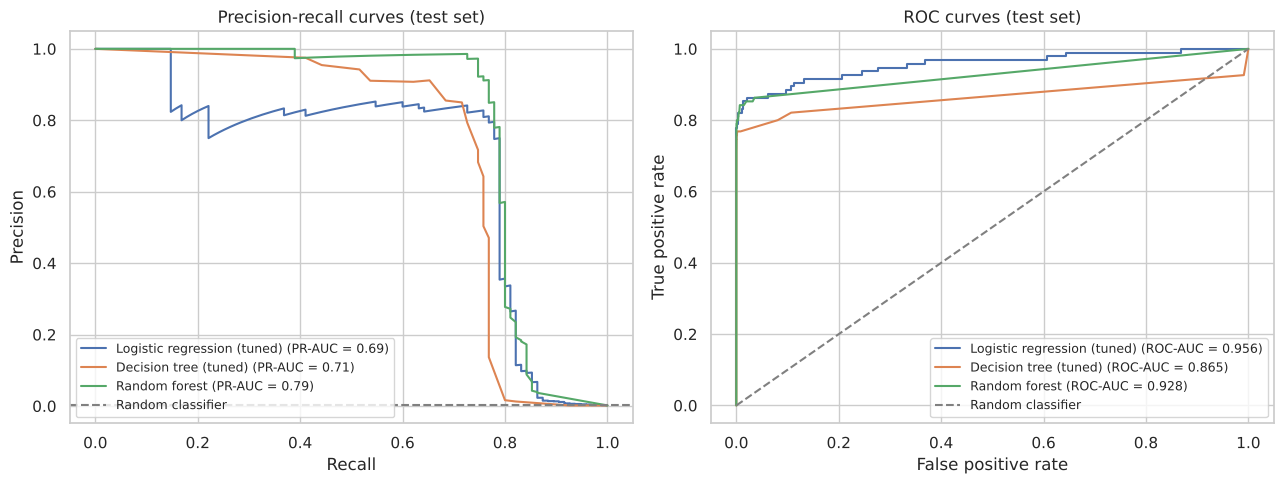

In [19]:
from sklearn.metrics import precision_recall_curve, roc_curve

compare = ["Logistic regression (tuned)", "Decision tree (tuned)", "Random forest"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in compare:
    proba = fitted[name].predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, proba)
    axes[0].plot(recall, precision, label=f"{name} (PR-AUC = {results[name]['pr_auc']:.2f})")
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, label=f"{name} (ROC-AUC = {results[name]['roc_auc']:.3f})")

axes[0].axhline(y_test.mean(), color="grey", linestyle="--", label="Random classifier")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (test set)")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random classifier")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test set)")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[0] else "lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "pr_roc_curves.png", dpi=120)
plt.show()

Logistic regression has the best ROC curve but the weakest precision-recall curve of the three. With 95 frauds among almost 57,000 test transactions, even a false positive rate of 1 % means about 570 false alarms, six times the number of frauds; the ROC curve hides this, the precision-recall curve shows it.

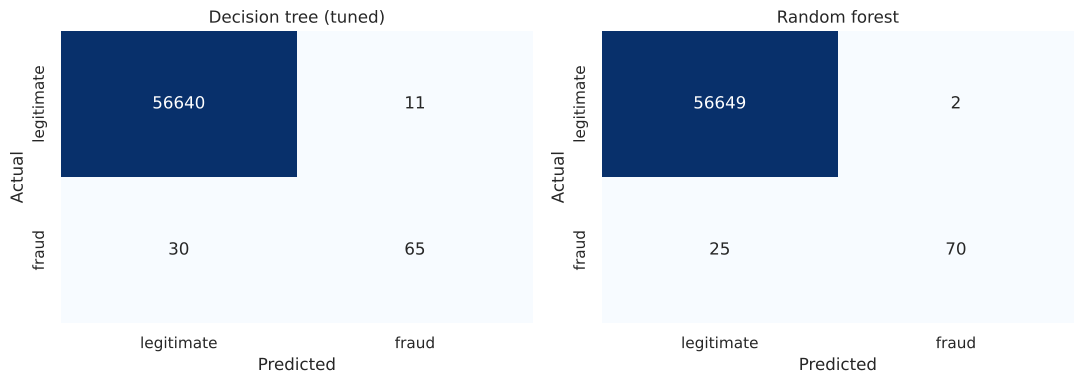

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["Decision tree (tuned)", "Random forest"]):
    pred = fitted[name].predict(X_test)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["legitimate", "fraud"], yticklabels=["legitimate", "fraud"])
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
fig.tight_layout()
plt.show()

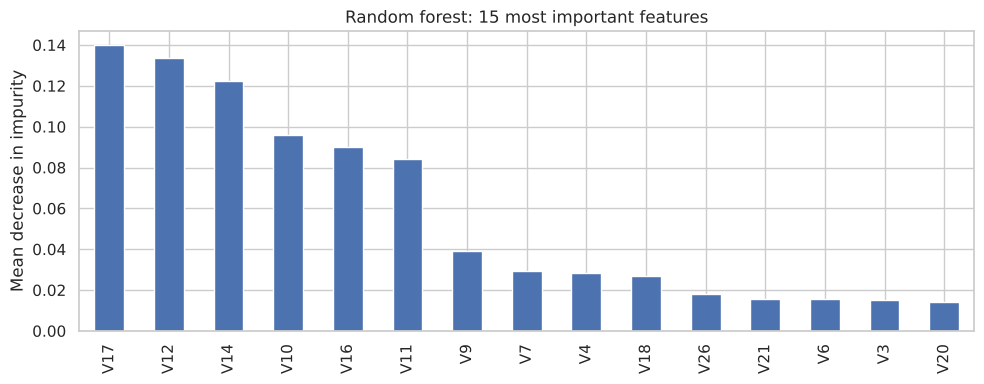

In [21]:
importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
importances.head(15).plot.bar(ax=ax)
ax.set(title="Random forest: 15 most important features", ylabel="Mean decrease in impurity")
fig.tight_layout()
plt.show()

## 11. Conclusions

- **The random forest is the best model:** PR-AUC 0.79, it catches 70 of the 95 test frauds with only 2 false alarms among 56,651 legitimate transactions.
- **Tuning made the decision tree usable.** The unrestricted tree overfits (PR-AUC 0.49); limiting the depth to 10 and requiring at least 20 samples per leaf raises PR-AUC to 0.71 and cuts false alarms from 26 to 11 at the same recall.
- **Cross-validation chose not to use SMOTE** for either model. Oversampling raised recall but cost much more in precision than it gained.
- **ROC-AUC alone is misleading here.** Logistic regression has the highest ROC-AUC (0.956) but the lowest PR-AUC of the three tuned models, because ROC-AUC barely reflects false alarms when legitimate transactions outnumber frauds 600 to 1.
- **About 20 % of frauds look like legitimate transactions** to all models: every precision-recall curve collapses at a recall of about 0.8. Catching these would need more information than the anonymised features provide (e.g. card history).
- The default threshold of 0.5 is not necessarily the right one; in practice it would be set from the cost of a missed fraud vs. the cost of reviewing a false alarm.